<a href="https://colab.research.google.com/github/rimlazrek1/Smart_Office_Occupancy_Detection/blob/main/Smart_Office_Occupancy_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###**Practice Project: Smart Office Occupancy Detection**


You are a Data Scientist at EcoSpace Solutions, an IoT (Internet of Things) startup that retrofits old office buildings with smart energy systems. Your team has installed sensors in a client's meeting rooms to measure Temperature, Humidity, Light intensity, and CO2 levels.

The goal is to automatically turn off the lights and HVAC (air conditioning) when a room is empty to save massive amounts of electricity.

You received the following message from the Lead Project Manager:


"Hi Team,

We need the machine learning model to predict whether a room is Occupied (1) or Empty (0) based on the sensor data. If we can get this right, we will save the client millions in energy costs.

Here is what I need you to do:
1. Run some visualizations on the sensor data. I want to know which sensor is the best indicator of human presence. Should we rely mostly on CO2, or is Light better?
2. Test out a few different algorithms. We need to know this model is robust and won't just fail when deployed to a new floor. Use a reliable testing method.
3. **The client's CEO gave us a strict requirement: The AI must be at least 97% accurate.** If it's less accurate than that, the lights will turn off while people are in meetings, and they will rip our system out of the building. Tinker with the models until you break that 97% threshold.

Can we hit their target?

Project Manager"



Your task is to translate the Project Manager's business requests into a Machine Learning pipeline.

Run the two cells below to install the UCI repository tool and load your dataset.

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ucimlrepo import fetch_ucirepo

# Fetch dataset
occupancy = fetch_ucirepo(id=357)

# Combine into one dataframe for easy EDA
df = occupancy.data.features[['Temperature','Humidity','Light','CO2','HumidityRatio']].copy()
df['Occupancy'] = occupancy.data.targets
df = df.apply(pd.to_numeric, errors='coerce')

df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.18,27.2720,426.0,721.25,0.004793,1.0
1,23.15,27.2675,429.5,714.00,0.004783,1.0
2,23.15,27.2450,426.0,713.50,0.004779,1.0
3,23.15,27.2000,426.0,708.25,0.004772,1.0
4,23.10,27.2000,426.0,704.50,0.004757,1.0


#### Task 1: Explanatory Data Analysis(EDA)

(1) Check the dataset for any missing values.

In [ ]:
df.shape

(20562, 6)

In [ ]:
df['Occupancy'].value_counts(dropna=False)

,count
Occupancy,
0.0,15810
1.0,4750
NaN,2


In [ ]:
df = df.dropna(subset=['Occupancy'])
X = df.drop('Occupancy', axis=1)
y = df['Occupancy']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0, stratify=y)

In [ ]:
X_train.isnull().sum()


,0
Temperature,0
Humidity,0
Light,0
CO2,0
HumidityRatio,0


In [ ]:
X_test.isnull().sum()

,0
Temperature,0
Humidity,0
Light,0
CO2,0
HumidityRatio,0


(2) Create at least two different types of visualizations (e.g. boxplots comparing CO2 levels when Occupied vs Empty, a scatter plot, or a correlation heatmap) using `matplotlib` or `seaborn`.

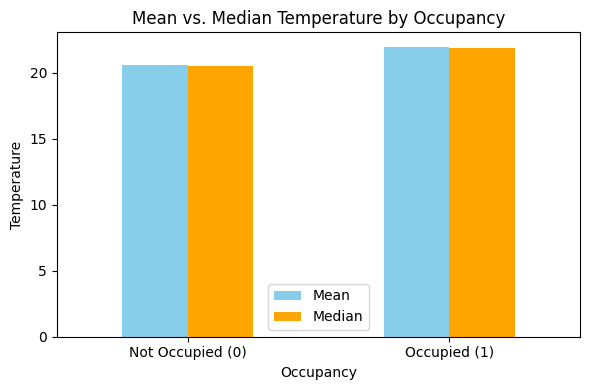

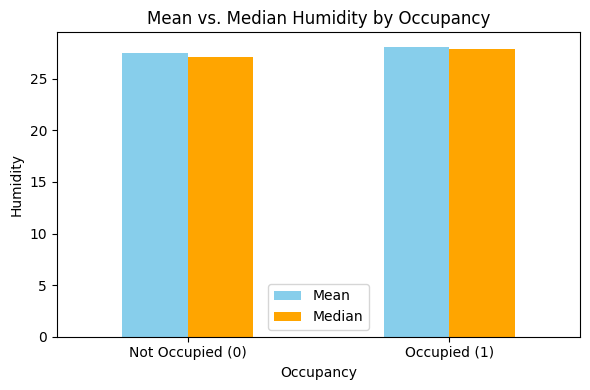

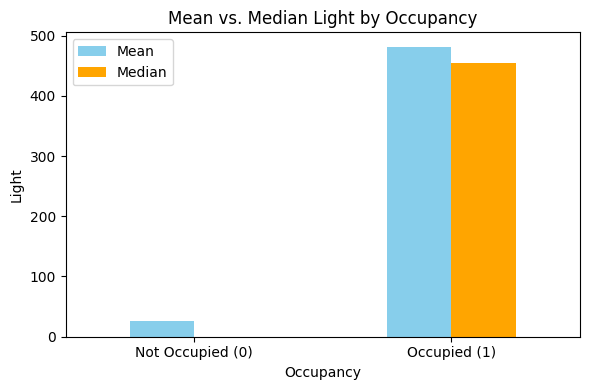

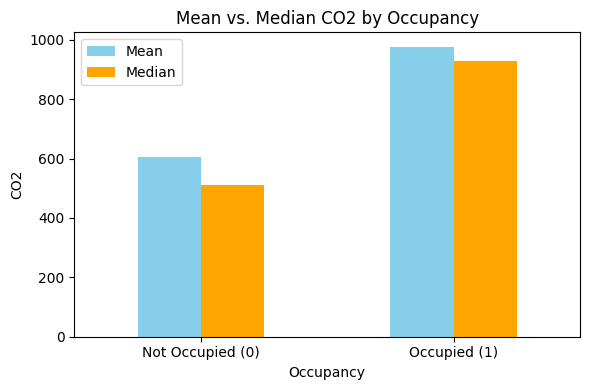

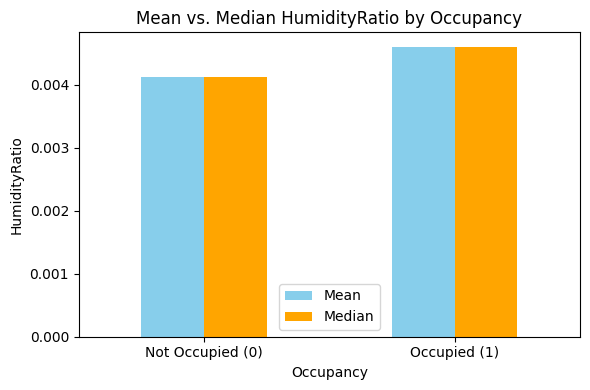

In [ ]:
for col in X_train.columns:
  # 1. Calculate both mean and median grouped by occupancy
  stats_df = X_train.groupby(y_train)[col].agg(['mean', 'median'])

  # 2. Plot them side-by-side (Pandas does this automatically for multi-column dataframes)
  stats_df.plot(kind='bar', figsize=(6, 4), color=['skyblue', 'orange'])

  # 3. Format the chart
  plt.title(f'Mean vs. Median {col} by Occupancy')
  plt.xlabel('Occupancy')
  plt.ylabel(col)
  plt.xticks(
      ticks=[0, 1], labels=['Not Occupied (0)', 'Occupied (1)'], rotation=0
  )
  plt.legend(['Mean', 'Median'])
  plt.tight_layout()
  plt.show()

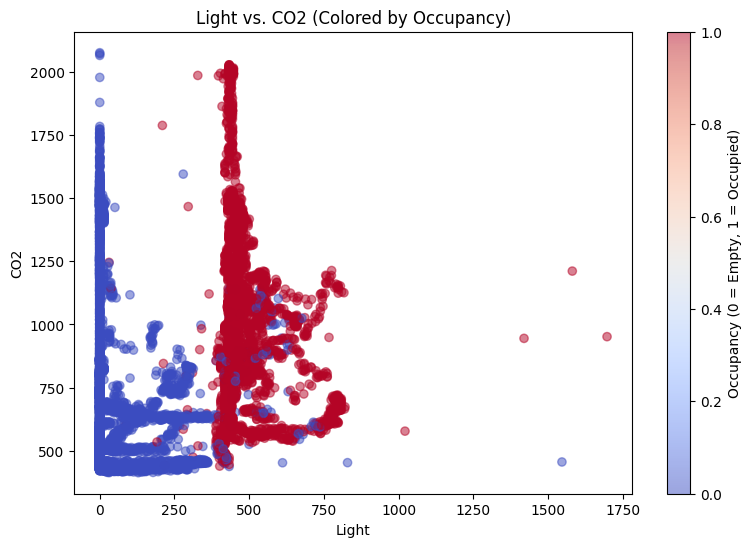

In [ ]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train['Light'], X_train['CO2'], c=y_train, cmap='coolwarm', alpha=0.5
)

plt.xlabel('Light')
plt.ylabel('CO2')
plt.title('Light vs. CO2 (Colored by Occupancy)')
plt.colorbar(scatter, label='Occupancy (0 = Empty, 1 = Occupied)')
plt.show()

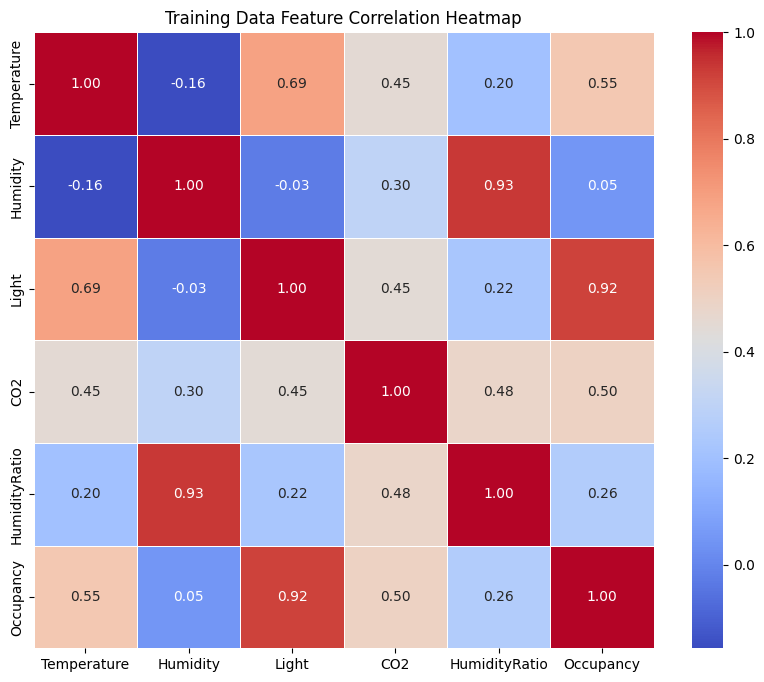

In [ ]:
train_data = X_train.copy()
train_data['Occupancy'] = y_train

plt.figure(figsize=(10, 8))

corr_matrix = train_data.corr()

sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)

plt.title('Training Data Feature Correlation Heatmap')
plt.show()

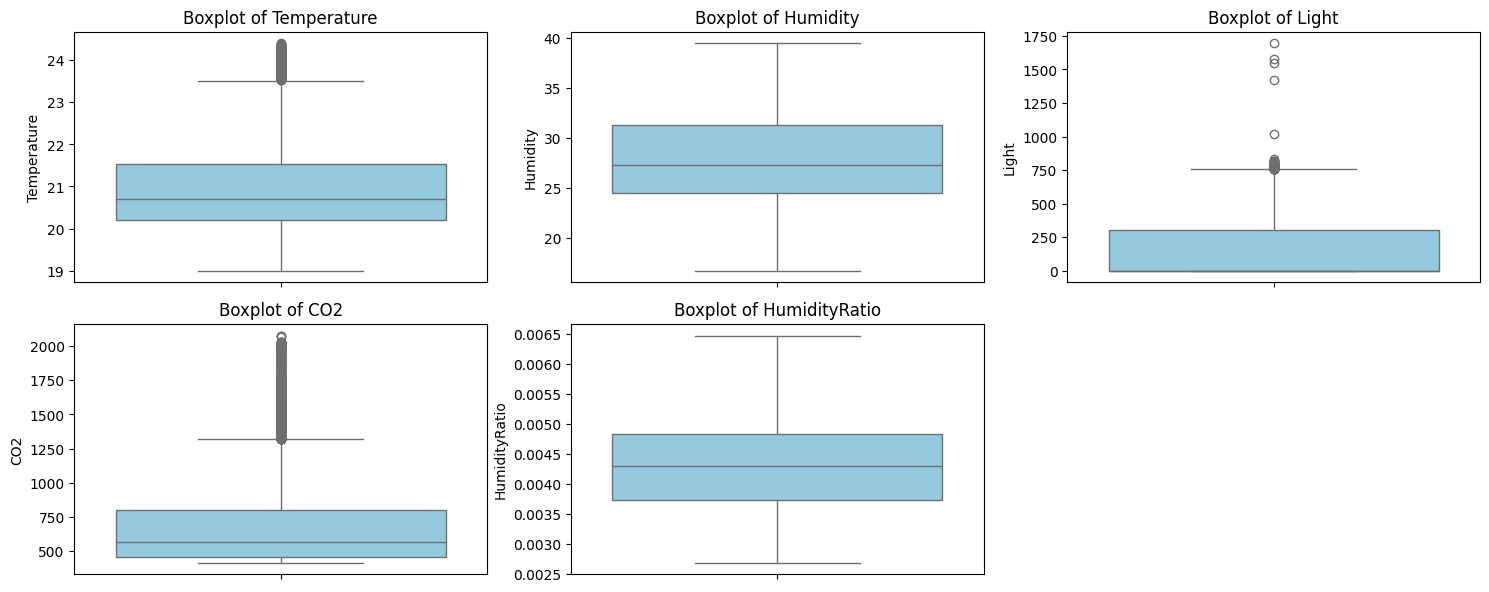

In [ ]:
plt.figure(figsize=(15, 6))

for i, col in enumerate(X_train.columns, 1):
  plt.subplot(2, 3, i)
  sns.boxplot(y=X_train[col], color='skyblue')
  plt.title(f'Boxplot of {col}')
  plt.ylabel(col)

plt.tight_layout()
plt.show()

(3) Which sensor data seems to have the strongest relationship with whether a room is occupied?

1- light (strongest)  
2- co2   
3- temperature   
4- HumidityRatio   
5- Humidity (weakest)   

#### Task 2: Model Selection and Baseline Testing

Test at least three different classification algorithms we have covered (e.g. Logistic Regression, Decision Trees, KNN, or SVM). Remember that the Project Manager asked for a guarantee of reliability. Evaluate the performance of the models using accuracy via k-fold validation. Print out the baseline average accuracy for each model.

Hint: Look at your raw data. CO2 levels are in the hundreds or thousands, while Humidity Ratio is a tiny decimal like 0.004. If you are using models that measure distance, like KNN or SVM, what must you do to the data first?

In [ ]:
# Standardization process
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

# Creating the three models i chose
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import  KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

linear = LogisticRegression()
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier()

# Conducting 5-fold cross validation on the models (only on the training data!)
# Pair models with their respective data
model_configs = [
    (linear, X_train_std),
    (knn, X_train_std),
    (dt, X_train)        # Unscaled data for the tree!
]

for model, data in model_configs:
    scores = cross_val_score(model, data, y_train, cv=5)
    print(f'{type(model).__name__} -> Scores: {scores.mean():.3f} +/- {scores.std():.3f}')


LogisticRegression -> Scores: 0.989 +/- 0.001
KNeighborsClassifier -> Scores: 0.992 +/- 0.001
DecisionTreeClassifier -> Scores: 0.990 +/- 0.001


#### Task 3: Hyperparameter Tuning

Choose your best performing model from Task 2. Define a grid of hyperparameters for this model. For example, you can test different values of `max_depth` for a Decision Tree, `n_neighbors` for KNN, or `C` for SVM. Conduct hyperparameter tuning to squeeze out the highest accuracy score you possibly can, the print your final accuracy score.

In [ ]:
# Prepare parameters for GridSearchCV
param_grid = {
    'n_neighbors': list(range(5, 22, 2))
}

#Initialize GridSearchCV
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5
)

# Perform hyperparameter tuning and build the best model
gs.fit(X_train_std, y_train)

# Display the results for both the training and testing data
print('Best cross-validation score: {:.3f}'.format(gs.best_score_))
print('Best parameters: {}'.format(gs.best_params_))
print('Test set score: {:.3f}'.format(gs.score(X_test_std, y_test)))

Best cross-validation score: 0.992
Best parameters: {'n_neighbors': 5}
Test set score: 0.993
